In [ ]:
import os
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

# TensorFlow and Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Dropout, BatchNormalization
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
np.random.seed(42)
tf.random.set_seed(42)

In [ ]:
RAVDESS_PATH = '/content/drive/MyDrive/ASR_project/MONO_Lingual/RAVDESS/AudioFiles_AUG' # English dataset
IESC_PATH = "/content/drive/MyDrive/hindi_dataset_kaggle/Indian Emotional Speech Corpora (IESC)" # Hindi dataset


In [ ]:
SAMPLE_RATE = 16000
DURATION = 3.0  # seconds
N_MFCC = 40


In [ ]:
HINDI_EMOTION_MAP = {
    'anger': 'angry',
    'happy': 'happy',
    'sad': 'sad',
    'fear': 'fear',
    'neutral': 'neutral'
}

# Final emotion labels (5 classes)
EMOTION_LABELS = {
    'angry': 0,
    'sad': 1,
    'happy': 2,
    'fear': 3,
    'neutral': 4
}

# Model parameters
N_FOLDS = 5
BATCH_SIZE = 32
EPOCHS = 50
PATIENCE = 15

# Define a maximum number of time steps for MFCC features
MAX_TIME_STEPS = 128

In [ ]:
# =====================================================================
# DATA AUGMENTATION FUNCTIONS (FOR HINDI ONLY)
# =====================================================================

def add_white_noise(audio, noise_factor=0.005):
    """Add white noise to audio"""
    noise = np.random.randn(len(audio))
    augmented_audio = audio + noise_factor * noise
    return augmented_audio.astype(np.float32)

def time_shift(audio, shift_max=0.2):
    """Shift audio in time"""
    shift = int(np.random.uniform(-shift_max, shift_max) * len(audio))
    return np.roll(audio, shift)

def time_stretch(audio, rate=None):
    """Stretch or compress audio in time"""
    if rate is None:
        rate = np.random.uniform(0.8, 1.2)
    return librosa.effects.time_stretch(audio, rate=rate)

def pitch_shift(audio, sr, n_steps=None):
    """Shift pitch of audio"""
    if n_steps is None:
        n_steps = np.random.randint(-3, 4)
    return librosa.effects.pitch_shift(audio, sr=sr, n_steps=n_steps)

def augment_audio(audio, sr):
    """Apply random augmentation to audio"""
    augmentation_type = np.random.choice(['noise', 'shift', 'stretch', 'pitch'])

    if augmentation_type == 'noise':
        return add_white_noise(audio)
    elif augmentation_type == 'shift':
        return time_shift(audio)
    elif augmentation_type == 'stretch':
        return time_stretch(audio)
    else:
        return pitch_shift(audio, sr)


In [ ]:
# =====================================================================
# AUDIO PROCESSING FUNCTIONS
# =====================================================================

def load_and_preprocess_audio(file_path, sr=SAMPLE_RATE, duration=DURATION):
    """Load and preprocess audio to fixed duration"""
    try:
        audio, _ = librosa.load(file_path, sr=sr, duration=duration)

        # Pad or truncate to fixed length
        target_length = int(sr * duration)
        if len(audio) < target_length:
            audio = np.pad(audio, (0, target_length - len(audio)), mode='constant')
        else:
            audio = audio[:target_length]

        return audio
    except Exception as e:
        print(f"Error loading {file_path}: {e}")
        return None

def extract_mfcc(audio, sr=SAMPLE_RATE, n_mfcc=N_MFCC):
    """Extract MFCC features"""
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=n_mfcc)
    return mfcc.T  # Transpose to (time_steps, n_mfcc)

def extract_wmfcc(audio, sr=SAMPLE_RATE, n_mfcc=N_MFCC):
    """Extract Weighted MFCC features with linearly increasing weights"""
    mfcc = librosa.feature.mfcc(y=audio, sr=sr, n_mfcc=n_mfcc)

    # Apply linearly increasing weights
    weights = np.linspace(1, 2, n_mfcc).reshape(-1, 1)
    wmfcc = mfcc * weights

    return wmfcc.T  # Transpose to (time_steps, n_mfcc)


In [ ]:
# =====================================================================
# DATA LOADING FUNCTIONS
# =====================================================================

def extract_ravdess_emotion(filename):
    """
    Extract emotion from RAVDESS filename
    Format: 03-01-XX-01-01-01-01.wav
    Third field (XX) is emotion: 01=neutral, 03=happy, 04=sad, 05=angry, 06=fear
    """
    try:
        parts = filename.split('-')
        if len(parts) >= 3:
            emotion_code = int(parts[2])
            emotion_map = {
                1: 'neutral',
                3: 'happy',
                4: 'sad',
                5: 'angry',
                6: 'fear'
            }
            return emotion_map.get(emotion_code, None)
    except:
        pass
    return None

def load_ravdess_data(dataset_path):
    """
    Load RAVDESS dataset (English, already augmented)
    NO runtime augmentation should be applied
    """
    print("="*70)
    print("Loading RAVDESS dataset (English)...")
    print("="*70)

    audio_files = []

    for root, dirs, files in os.walk(dataset_path):
        for file in files:
            if file.endswith('.wav'):
                emotion = extract_ravdess_emotion(file)
                if emotion in EMOTION_LABELS:
                    file_path = os.path.join(root, file)
                    audio_files.append({
                        'path': file_path,
                        'emotion': emotion,
                        'language': 'english'
                    })

    print(f"✓ Loaded {len(audio_files)} RAVDESS audio files (already augmented)")
    print(f"✓ NO runtime augmentation applied to RAVDESS")

    return audio_files

def load_iesc_data(dataset_path):
    """
    Load IESC dataset (Hindi) from Speaker-X/emotion/ structure
    This function loads ORIGINAL files only (augmentation happens later)

    ROBUST EMOTION MAPPING:
    - Handles variations: anger/angry, happy/happiness, sad/sadness, fear/fearful, neutral
    - Case-insensitive matching
    - Partial string matching for flexibility

    Structure:
    IESC/
      Speaker-1/
        Anger/ (or angry/Angry)
        Happiness/ (or happy/Happy)
        Sadness/ (or sad/Sad)
        Fear/ (or fearful/Fearful)
        Neutral/
      Speaker-2/
      ...
    """
    print("="*70)
    print("Loading IESC dataset (Hindi)...")
    print("="*70)

    audio_files = []

    # ROBUST EMOTION MAPPING - handles all variations
    EMOTION_MAPPING = {
        'angry': ['anger', 'angry'],
        'happy': ['happiness', 'happy', 'hap'],
        'sad': ['sadness', 'sad'],
        'fear': ['fear', 'fearful'],
        'neutral': ['neutral', 'neu']
    }

    def map_emotion_folder_to_label(folder_name):
        """
        Map emotion folder name to standardized label
        Returns: emotion label or None if not recognized
        """
        folder_lower = folder_name.lower().strip()

        for standard_emotion, variations in EMOTION_MAPPING.items():
            for variation in variations:
                if variation in folder_lower:
                    return standard_emotion

        return None

    # Iterate through Speaker folders
    speaker_folders = sorted([f for f in os.listdir(dataset_path)
                             if os.path.isdir(os.path.join(dataset_path, f))
                             and f.lower().startswith('speaker')])

    if not speaker_folders:
        print("WARNING: No Speaker folders found!")
        return audio_files

    print(f"Found {len(speaker_folders)} speaker folders")

    for speaker_folder in speaker_folders:
        speaker_path = os.path.join(dataset_path, speaker_folder)

        print(f"Processing {speaker_folder}...")

        # Get all subdirectories (emotion folders)
        try:
            emotion_folders = [f for f in os.listdir(speaker_path)
                             if os.path.isdir(os.path.join(speaker_path, f))]
        except Exception as e:
            print(f"  Error reading {speaker_folder}: {e}")
            continue

        # Process each emotion folder
        for emotion_folder in emotion_folders:
            emotion_path = os.path.join(speaker_path, emotion_folder)

            # Map folder name to standard emotion label
            emotion = map_emotion_folder_to_label(emotion_folder)

            if emotion is None:
                print(f"  Skipping unknown emotion folder: {emotion_folder}")
                continue

            # Count files for this emotion
            wav_count = 0

            # Load all audio files in this emotion folder
            try:
                files = os.listdir(emotion_path)
            except Exception as e:
                print(f"  Error reading {emotion_folder}: {e}")
                continue

            for file in files:
                if file.endswith('.wav'):
                    file_path = os.path.join(emotion_path, file)
                    audio_files.append({
                        'path': file_path,
                        'emotion': emotion,
                        'language': 'hindi',
                        'speaker': speaker_folder
                    })
                    wav_count += 1

            if wav_count > 0:
                print(f"  ✓ {emotion_folder} → {emotion}: {wav_count} files")

    print(f"\n✓ Loaded {len(audio_files)} ORIGINAL Hindi audio files")
    print(f"✓ Runtime augmentation will be applied (3 versions per sample)")
    print(f"✓ Expected Hindi samples after augmentation: {len(audio_files) * 4}")

    # Show distribution by emotion
    if audio_files:
        print(f"\nEmotion distribution in IESC:")
        emotion_counts = {}
        for item in audio_files:
            emotion_counts[item['emotion']] = emotion_counts.get(item['emotion'], 0) + 1
        for emotion in sorted(emotion_counts.keys()):
            print(f"  {emotion}: {emotion_counts[emotion]} files")

    return audio_files

def load_all_data():
    """Load both datasets and show statistics"""
    print("\n" + "="*70)
    print("LOADING ALL DATASETS")
    print("="*70 + "\n")

    # Load RAVDESS (English) - already augmented
    ravdess_data = load_ravdess_data(RAVDESS_PATH)

    print()

    # Load IESC (Hindi) - original files only
    iesc_data = load_iesc_data(IESC_PATH)

    print("\n" + "="*70)
    print("DATASET LOADING SUMMARY")
    print("="*70)
    print(f"RAVDESS (English) original count: {len(ravdess_data)}")
    print(f"IESC (Hindi) original count: {len(iesc_data)}")
    print(f"IESC (Hindi) after augmentation (×4): {len(iesc_data) * 4}")
    print(f"Expected TOTAL samples: {len(ravdess_data) + len(iesc_data) * 4}")
    print("="*70 + "\n")

    return ravdess_data, iesc_data

In [ ]:
# =====================================================================
# FEATURE EXTRACTION WITH AUGMENTATION
# =====================================================================

def extract_features_with_augmentation(ravdess_data, iesc_data, feature_type='mfcc'):
    """
    Extract features from both datasets
    - RAVDESS: No augmentation (already augmented)
    - IESC: Apply augmentation (3 augmented versions per sample)

    Parameters:
    - ravdess_data: list of RAVDESS audio file info
    - iesc_data: list of IESC audio file info
    - feature_type: 'mfcc' or 'wmfcc'

    Returns:
    - features: numpy array of shape (total_samples, time_steps, n_mfcc)
    - labels: numpy array of emotion labels
    - language_tags: list of language for each sample
    """
    print("\n" + "="*70)
    print(f"EXTRACTING {feature_type.upper()} FEATURES")
    print("="*70)

    features = []
    labels = []
    language_tags = []

    # ===== PROCESS RAVDESS (NO AUGMENTATION) =====
    print(f"\nProcessing RAVDESS (English) - NO augmentation...")
    ravdess_count = 0

    for idx, item in enumerate(ravdess_data):
        if idx % 500 == 0:
            print(f"  RAVDESS: {idx}/{len(ravdess_data)}...")

        # Load audio
        audio = load_and_preprocess_audio(item['path'])
        if audio is None:
            continue

        # Extract features (NO augmentation)
        if feature_type == 'mfcc':
            feat = extract_mfcc(audio)
        elif feature_type == 'wmfcc':
            feat = extract_wmfcc(audio)
        else:
            raise ValueError(f"Unknown feature type: {feature_type}")

        # Pad or truncate features to MAX_TIME_STEPS
        if feat.shape[0] < MAX_TIME_STEPS:
            # Pad with zeros
            pad_width = ((0, MAX_TIME_STEPS - feat.shape[0]), (0, 0))
            feat = np.pad(feat, pad_width, mode='constant')
        elif feat.shape[0] > MAX_TIME_STEPS:
            # Truncate
            feat = feat[:MAX_TIME_STEPS, :]

        features.append(feat)
        labels.append(EMOTION_LABELS[item['emotion']])
        language_tags.append('english')
        ravdess_count += 1

    print(f"✓ RAVDESS samples processed: {ravdess_count}")

    # ===== PROCESS IESC (WITH AUGMENTATION) =====
    print(f"\nProcessing IESC (Hindi) - WITH augmentation (3 versions per sample)...")
    hindi_original_count = 0
    hindi_augmented_count = 0

    for idx, item in enumerate(iesc_data):
        if idx % 100 == 0:
            print(f"  IESC: {idx}/{len(iesc_data)}...")

        # Load audio
        audio = load_and_preprocess_audio(item['path'])
        if audio is None:
            continue

        # Process original audio
        if feature_type == 'mfcc':
            feat_original = extract_mfcc(audio)
        elif feature_type == 'wmfcc':
            feat_original = extract_wmfcc(audio)

        # Pad or truncate features to MAX_TIME_STEPS
        if feat_original.shape[0] < MAX_TIME_STEPS:
            # Pad with zeros
            pad_width = ((0, MAX_TIME_STEPS - feat_original.shape[0]), (0, 0))
            feat_original = np.pad(feat_original, pad_width, mode='constant')
        elif feat_original.shape[0] > MAX_TIME_STEPS:
            # Truncate
            feat_original = feat_original[:MAX_TIME_STEPS, :]

        features.append(feat_original)
        labels.append(EMOTION_LABELS[item['emotion']])
        language_tags.append('hindi')
        hindi_original_count += 1

        # Create 3 augmented versions
        for aug_idx in range(3):
            aug_audio = augment_audio(audio.copy(), SAMPLE_RATE)

            if feature_type == 'mfcc':
                feat_aug = extract_mfcc(aug_audio)
            elif feature_type == 'wmfcc':
                feat_aug = extract_wmfcc(aug_audio)

            # Pad or truncate features to MAX_TIME_STEPS
            if feat_aug.shape[0] < MAX_TIME_STEPS:
                # Pad with zeros
                pad_width = ((0, MAX_TIME_STEPS - feat_aug.shape[0]), (0, 0))
                feat_aug = np.pad(feat_aug, pad_width, mode='constant')
            elif feat_aug.shape[0] > MAX_TIME_STEPS:
                # Truncate
                feat_aug = feat_aug[:MAX_TIME_STEPS, :]

            features.append(feat_aug)
            labels.append(EMOTION_LABELS[item['emotion']])
            language_tags.append('hindi')
            hindi_augmented_count += 1

    print(f"✓ IESC original samples: {hindi_original_count}")
    print(f"✓ IESC augmented samples: {hindi_augmented_count}")
    print(f"✓ IESC TOTAL samples: {hindi_original_count + hindi_augmented_count}")

    # Convert to numpy arrays
    features = np.array(features, dtype=np.float32)
    labels = np.array(labels, dtype=np.int32)

    print("\n" + "="*70)
    print("FEATURE EXTRACTION COMPLETE")
    print("="*70)
    print(f"Total samples: {len(features)}")
    print(f"  - RAVDESS (English): {ravdess_count}")
    print(f"  - IESC (Hindi): {hindi_original_count + hindi_augmented_count}")
    print(f"Feature shape: {features.shape}")
    print(f"Labels shape: {labels.shape}")
    print("="*70 + "\n")

    # Show emotion distribution
    print("Emotion distribution:")
    emotion_counts = {}
    for label in labels:
        emotion_name = [k for k, v in EMOTION_LABELS.items() if v == label][0]
        emotion_counts[emotion_name] = emotion_counts.get(emotion_name, 0) + 1

    for emotion, count in sorted(emotion_counts.items()):
        print(f"  {emotion}: {count}")
    print()

    return features, labels, language_tags

def normalize_features(features_train, features_test):
    """Apply fold-wise normalization (using only training mean/std)"""
    mean = np.mean(features_train, axis=(0, 1), keepdims=True)
    std = np.std(features_train, axis=(0, 1), keepdims=True)

    features_train_norm = (features_train - mean) / (std + 1e-8)
    features_test_norm = (features_test - mean) / (std + 1e-8)

    return features_train_norm, features_test_norm


In [ ]:
# =====================================================================
# MODEL BUILDING FUNCTIONS
# =====================================================================

def build_lstm_model(input_shape, n_classes=5):
    """Build LSTM model"""
    model = Sequential([
        LSTM(128, return_sequences=True, input_shape=input_shape),
        BatchNormalization(),
        Dropout(0.3),

        LSTM(64, return_sequences=True),
        BatchNormalization(),
        Dropout(0.3),

        LSTM(32),
        BatchNormalization(),
        Dropout(0.3),

        Dense(64, activation='relu'),
        Dropout(0.3),

        Dense(n_classes, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

def build_bilstm_model(input_shape, n_classes=5):
    """Build Bidirectional LSTM model"""
    model = Sequential([
        Bidirectional(LSTM(128, return_sequences=True), input_shape=input_shape),
        BatchNormalization(),
        Dropout(0.3),

        Bidirectional(LSTM(64, return_sequences=True)),
        BatchNormalization(),
        Dropout(0.3),

        Bidirectional(LSTM(32)),
        BatchNormalization(),
        Dropout(0.3),

        Dense(64, activation='relu'),
        Dropout(0.3),

        Dense(n_classes, activation='softmax')
    ])

    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

# =====================================================================
# MODIFIED TRAINING - TRAIN ON BOTH, TEST ON RAVDESS ONLY
# =====================================================================

def train_test_on_ravdess_only(X_all, y_all, lang_tags_all, model_builder, model_name, n_folds=N_FOLDS):
    """
    Train on both RAVDESS and IESC, but test only on RAVDESS

    Strategy:
    1. Split RAVDESS data into K folds for testing
    2. For each fold:
       - Test set: RAVDESS fold
       - Train set: Remaining RAVDESS folds + ALL IESC data

    Parameters:
    - X_all: All features (RAVDESS + IESC)
    - y_all: All labels
    - lang_tags_all: Language tags for each sample
    - model_builder: Function to build the model
    - model_name: Name of the model
    - n_folds: Number of folds for cross-validation

    Returns:
    - fold_results: list of dictionaries with fold metrics
    - all_histories: list of training histories for each fold
    """
    print("\n" + "="*70)
    print(f"TRAINING: {model_name}")
    print(f"Strategy: Train on BOTH datasets, Test on RAVDESS only")
    print(f"Using {n_folds}-Fold Cross-Validation on RAVDESS")
    print("="*70)

    # Convert to numpy arrays
    lang_tags_all = np.array(lang_tags_all)

    # Separate RAVDESS and IESC indices
    ravdess_indices = np.where(lang_tags_all == 'english')[0]
    iesc_indices = np.where(lang_tags_all == 'hindi')[0]

    print(f"\nTotal RAVDESS samples: {len(ravdess_indices)}")
    print(f"Total IESC samples: {len(iesc_indices)}")

    # Extract RAVDESS data for K-fold splitting
    X_ravdess = X_all[ravdess_indices]
    y_ravdess = y_all[ravdess_indices]

    # Extract ALL IESC data (will be added to training set in each fold)
    X_iesc = X_all[iesc_indices]
    y_iesc = y_all[iesc_indices]

    # K-fold split on RAVDESS only
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=42)

    fold_results = []
    all_histories = []

    # Convert labels to categorical
    y_ravdess_cat = to_categorical(y_ravdess, num_classes=5)
    y_iesc_cat = to_categorical(y_iesc, num_classes=5)

    for fold, (train_idx_ravdess, test_idx_ravdess) in enumerate(skf.split(X_ravdess, y_ravdess), 1):
        print(f"\n{'─'*70}")
        print(f"FOLD {fold}/{n_folds}")
        print(f"{'─'*70}")

        # Test set: RAVDESS fold only
        X_test_fold = X_ravdess[test_idx_ravdess]
        y_test_fold = y_ravdess_cat[test_idx_ravdess]

        # Training set: Remaining RAVDESS folds + ALL IESC data
        X_train_ravdess = X_ravdess[train_idx_ravdess]
        y_train_ravdess = y_ravdess_cat[train_idx_ravdess]

        # Combine RAVDESS training data with ALL IESC data
        X_train_fold = np.concatenate([X_train_ravdess, X_iesc], axis=0)
        y_train_fold = np.concatenate([y_train_ravdess, y_iesc_cat], axis=0)

        print(f"Training samples: {len(X_train_fold)} (RAVDESS: {len(X_train_ravdess)}, IESC: {len(X_iesc)})")
        print(f"Test samples (RAVDESS only): {len(X_test_fold)}")

        # Normalize features (using training set statistics)
        X_train_norm, X_test_norm = normalize_features(X_train_fold, X_test_fold)

        # Build fresh model for this fold
        model = model_builder(input_shape=(X_train_norm.shape[1], X_train_norm.shape[2]))

        # Callbacks
        early_stop = EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True, verbose=1)
        reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1)

        # Train
        history = model.fit(
            X_train_norm, y_train_fold,
            validation_data=(X_test_norm, y_test_fold),
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=[early_stop, reduce_lr],
            verbose=1
        )

        # Evaluate
        train_loss, train_acc = model.evaluate(X_train_norm, y_train_fold, verbose=0)
        test_loss, test_acc = model.evaluate(X_test_norm, y_test_fold, verbose=0)

        print(f"\nFold {fold} Results:")
        print(f"  Train Accuracy: {train_acc:.4f}, Train Loss: {train_loss:.4f}")
        print(f"  Test Accuracy (RAVDESS):  {test_acc:.4f}, Test Loss:  {test_loss:.4f}")

        # Get predictions for confusion matrix
        y_pred = model.predict(X_test_norm, verbose=0)
        y_pred_classes = np.argmax(y_pred, axis=1)
        y_true_classes = np.argmax(y_test_fold, axis=1)

        fold_results.append({
            'fold': fold,
            'train_acc': train_acc,
            'train_loss': train_loss,
            'test_acc': test_acc,
            'test_loss': test_loss,
            'y_true': y_true_classes,
            'y_pred': y_pred_classes
        })

        all_histories.append(history)

    # Calculate average metrics
    avg_train_acc = np.mean([r['train_acc'] for r in fold_results])
    avg_test_acc = np.mean([r['test_acc'] for r in fold_results])
    avg_train_loss = np.mean([r['train_loss'] for r in fold_results])
    avg_test_loss = np.mean([r['test_loss'] for r in fold_results])

    print("\n" + "="*70)
    print(f"{model_name} - AVERAGE K-FOLD RESULTS")
    print("="*70)
    print(f"Average Train Accuracy: {avg_train_acc:.4f} (±{np.std([r['train_acc'] for r in fold_results]):.4f})")
    print(f"Average Test Accuracy (RAVDESS):  {avg_test_acc:.4f} (±{np.std([r['test_acc'] for r in fold_results]):.4f})")
    print(f"Average Train Loss:     {avg_train_loss:.4f}")
    print(f"Average Test Loss:      {avg_test_loss:.4f}")
    print("="*70 + "\n")

    return fold_results, all_histories


MULTILINGUAL SPEECH EMOTION RECOGNITION SYSTEM
TRAIN ON BOTH DATASETS, TEST ON HINDI (IESC) ONLY

LOADING ALL DATASETS


LOADING ALL DATASETS

Loading RAVDESS dataset (English)...
✓ Loaded 3456 RAVDESS audio files (already augmented)
✓ NO runtime augmentation applied to RAVDESS

Loading IESC dataset (Hindi)...
Found 8 speaker folders
Processing Speaker-1...
  ✓ Happy → happy: 10 files
  ✓ Neutral → neutral: 10 files
  ✓ Anger → angry: 10 files
  ✓ Fear → fear: 10 files
  ✓ Sad → sad: 10 files
Processing Speaker-2...
  ✓ Happy → happy: 10 files
  ✓ Anger → angry: 10 files
  ✓ Neutral → neutral: 10 files
  ✓ Fear → fear: 10 files
  ✓ Sad → sad: 10 files
Processing Speaker-3...
  ✓ Sad → sad: 10 files
  ✓ Neutral → neutral: 10 files
  ✓ Anger → angry: 10 files
  ✓ Happy → happy: 10 files
  ✓ Fear → fear: 10 files
Processing Speaker-4...
  ✓ Sad → sad: 10 files
  ✓ Neutral → neutral: 10 files
  ✓ Happy → happy: 10 files
  ✓ Anger → angry: 10 files
  ✓ Fear → fear: 10 files
Processing Spea

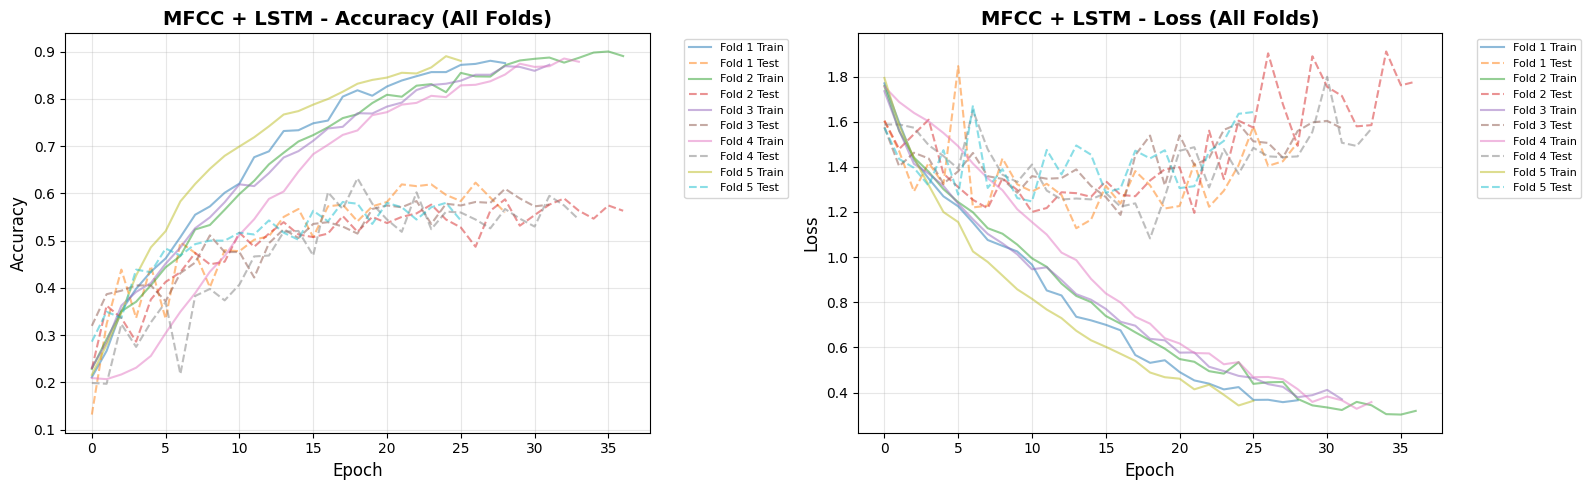

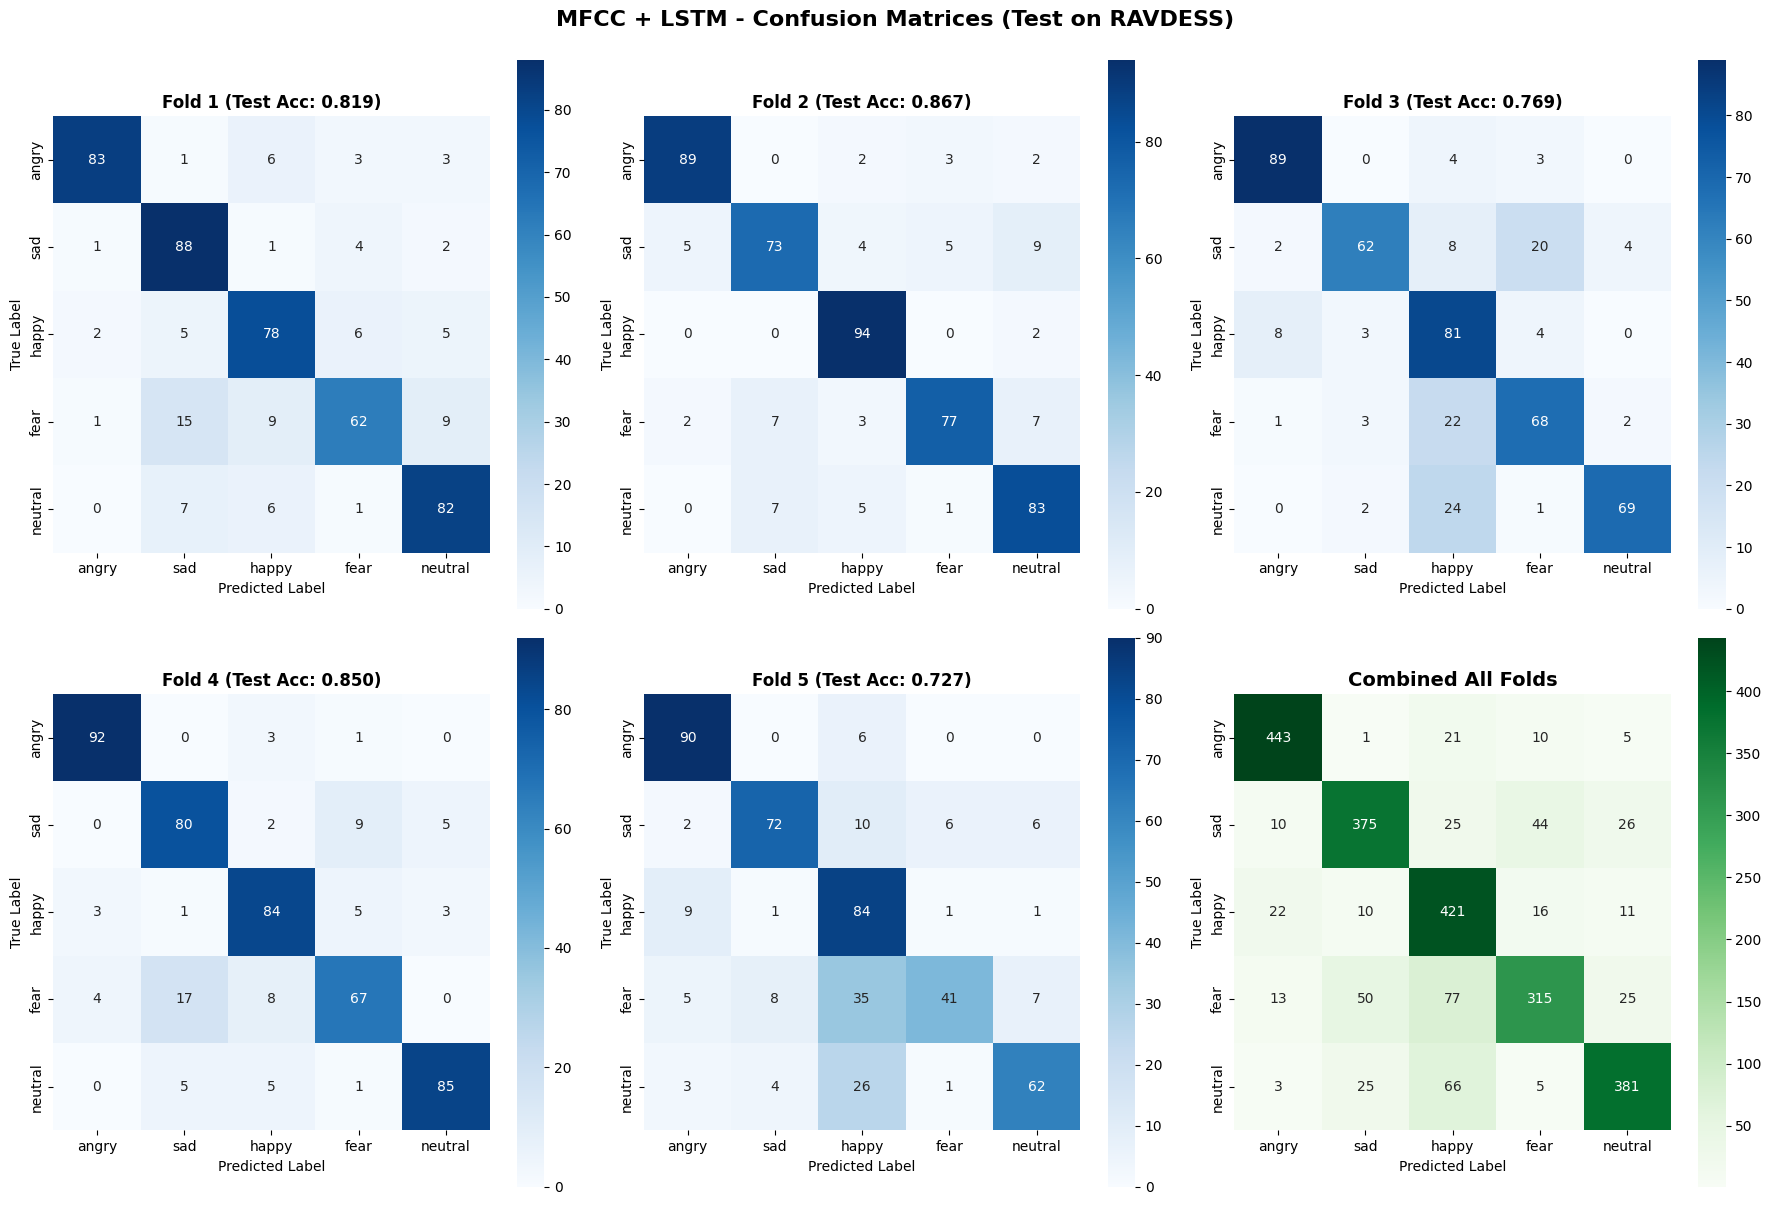


MFCC + LSTM - Classification Report (All Folds Combined - HINDI Test Set):
              precision    recall  f1-score   support

       angry     0.9022    0.9229    0.9125       480
         sad     0.8134    0.7812    0.7970       480
       happy     0.6902    0.8771    0.7725       480
        fear     0.8077    0.6562    0.7241       480
     neutral     0.8504    0.7937    0.8211       480

    accuracy                         0.8063      2400
   macro avg     0.8128    0.8063    0.8054      2400
weighted avg     0.8128    0.8063    0.8054      2400


██████████████████████████████████████████████████████████████████████
█  MODEL: MFCC + Bi-LSTM
██████████████████████████████████████████████████████████████████████

Using cached MFCC features...

TRAINING: MFCC + Bi-LSTM
Strategy: Train on BOTH datasets, Test on HINDI (IESC) only
Using 5-Fold Cross-Validation on HINDI samples

DEBUG: Type of lang_tags: <class 'numpy.ndarray'>
DEBUG: lang_tags dtype: <U7
DEBUG: lang_tags shape: 

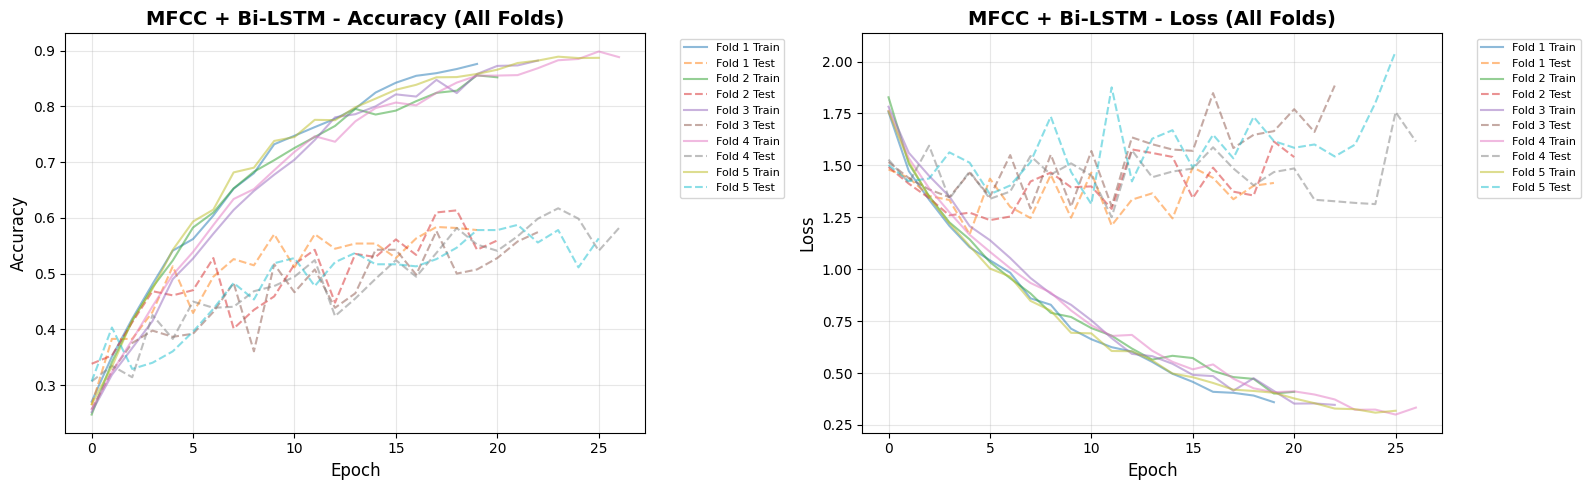

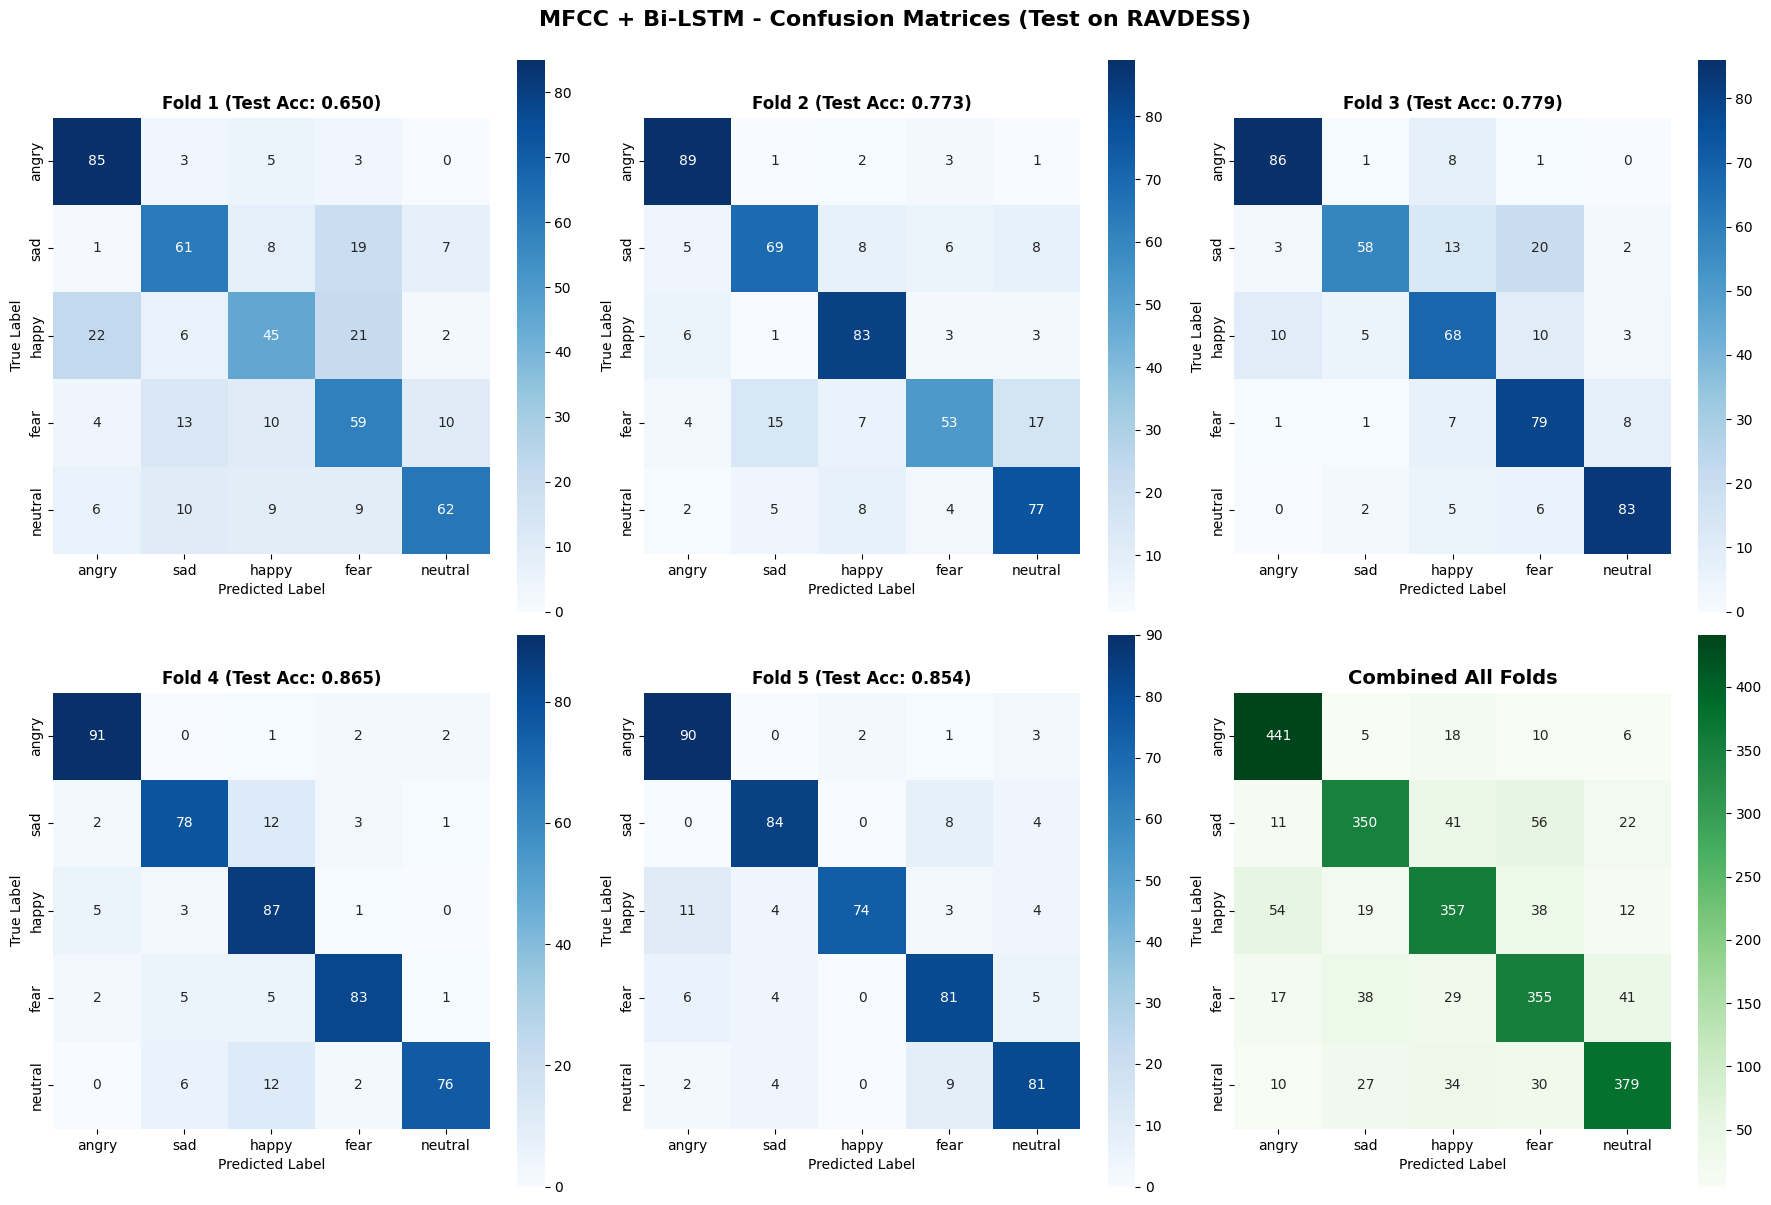


MFCC + Bi-LSTM - Classification Report (All Folds Combined - HINDI Test Set):
              precision    recall  f1-score   support

       angry     0.8274    0.9187    0.8707       480
         sad     0.7973    0.7292    0.7617       480
       happy     0.7453    0.7438    0.7445       480
        fear     0.7260    0.7396    0.7327       480
     neutral     0.8239    0.7896    0.8064       480

    accuracy                         0.7842      2400
   macro avg     0.7840    0.7842    0.7832      2400
weighted avg     0.7840    0.7842    0.7832      2400


██████████████████████████████████████████████████████████████████████
█  MODEL: WMFCC + LSTM
██████████████████████████████████████████████████████████████████████

EXTRACTING WMFCC FEATURES

Processing RAVDESS (English) - NO augmentation...
  RAVDESS: 0/3456...
  RAVDESS: 500/3456...
  RAVDESS: 1000/3456...
  RAVDESS: 1500/3456...
  RAVDESS: 2000/3456...
  RAVDESS: 2500/3456...
  RAVDESS: 3000/3456...
✓ RAVDESS samples proces

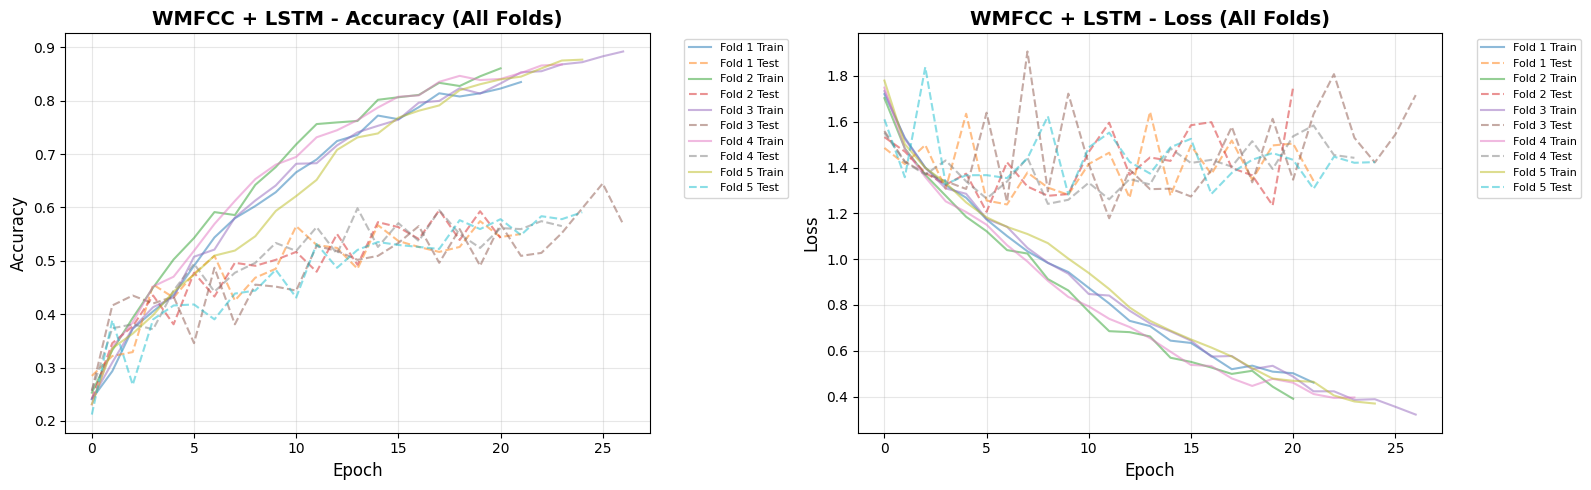

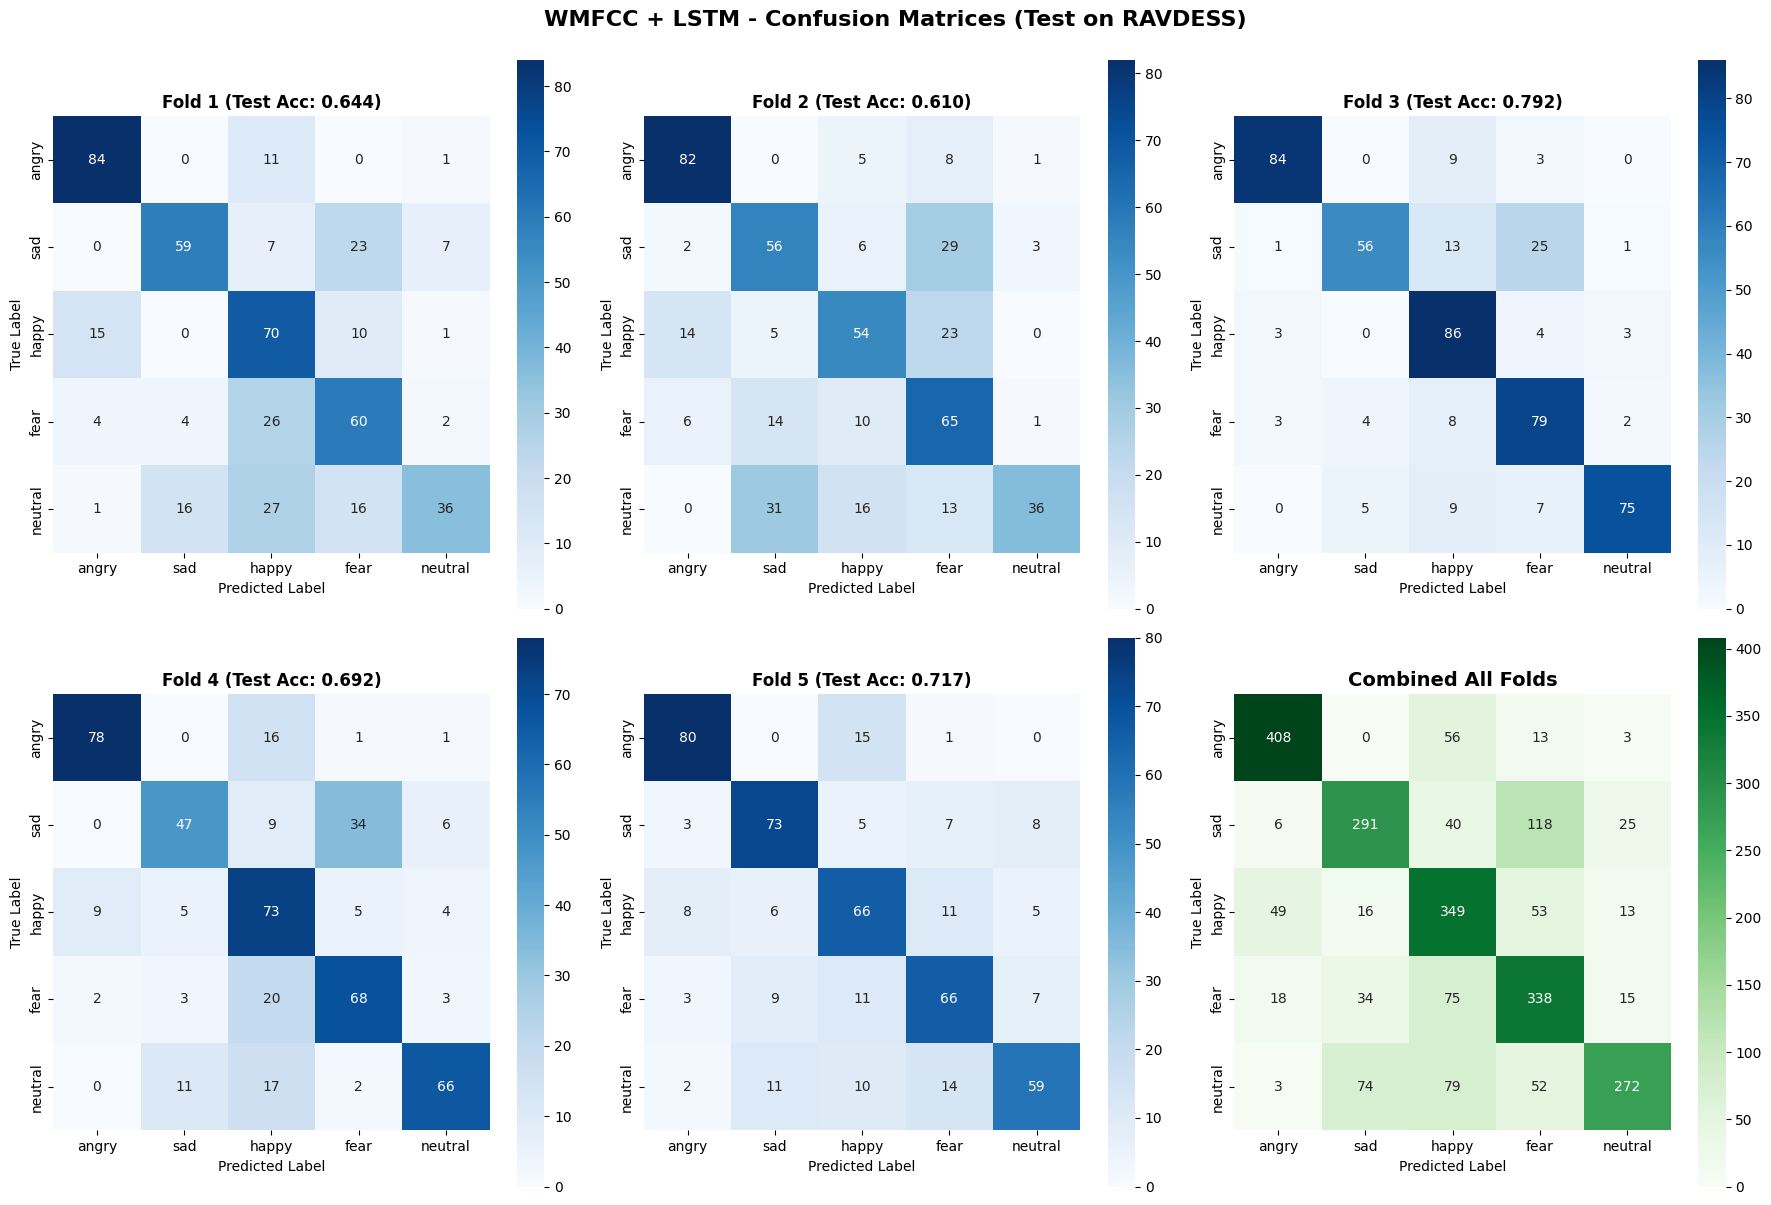


WMFCC + LSTM - Classification Report (All Folds Combined - HINDI Test Set):
              precision    recall  f1-score   support

       angry     0.8430    0.8500    0.8465       480
         sad     0.7012    0.6062    0.6503       480
       happy     0.5826    0.7271    0.6469       480
        fear     0.5889    0.7042    0.6414       480
     neutral     0.8293    0.5667    0.6733       480

    accuracy                         0.6908      2400
   macro avg     0.7090    0.6908    0.6917      2400
weighted avg     0.7090    0.6908    0.6917      2400


██████████████████████████████████████████████████████████████████████
█  MODEL: WMFCC + Bi-LSTM
██████████████████████████████████████████████████████████████████████

Using cached WMFCC features...

TRAINING: WMFCC + Bi-LSTM
Strategy: Train on BOTH datasets, Test on HINDI (IESC) only
Using 5-Fold Cross-Validation on HINDI samples

DEBUG: Type of lang_tags: <class 'numpy.ndarray'>
DEBUG: lang_tags dtype: <U7
DEBUG: lang_tags sha

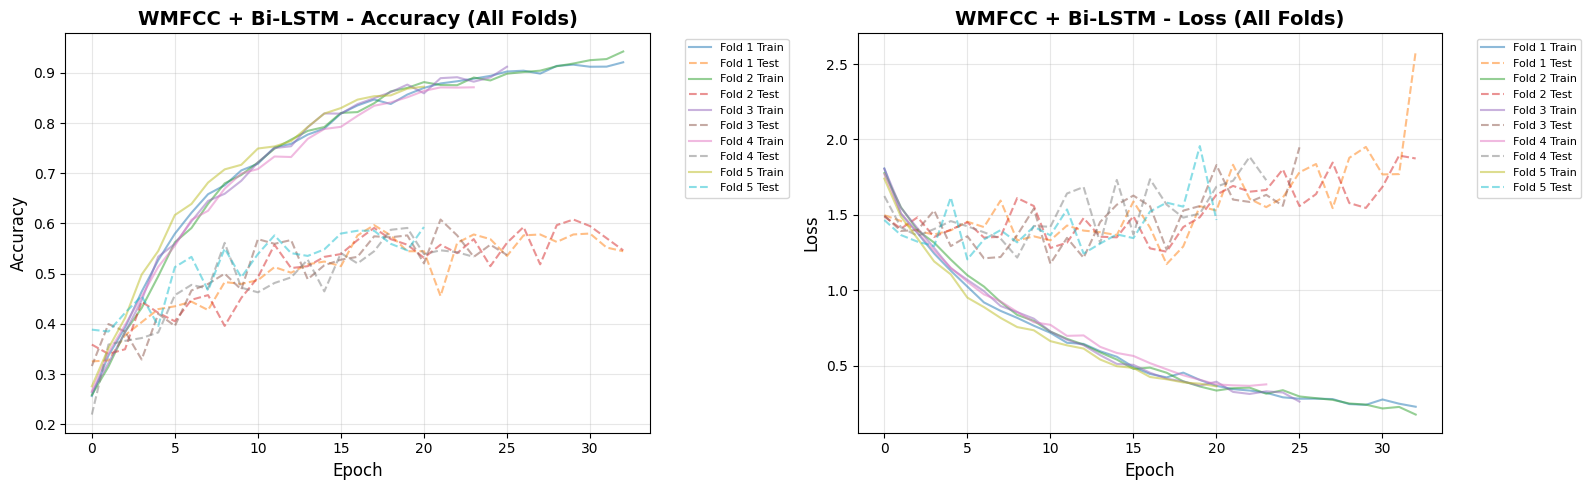

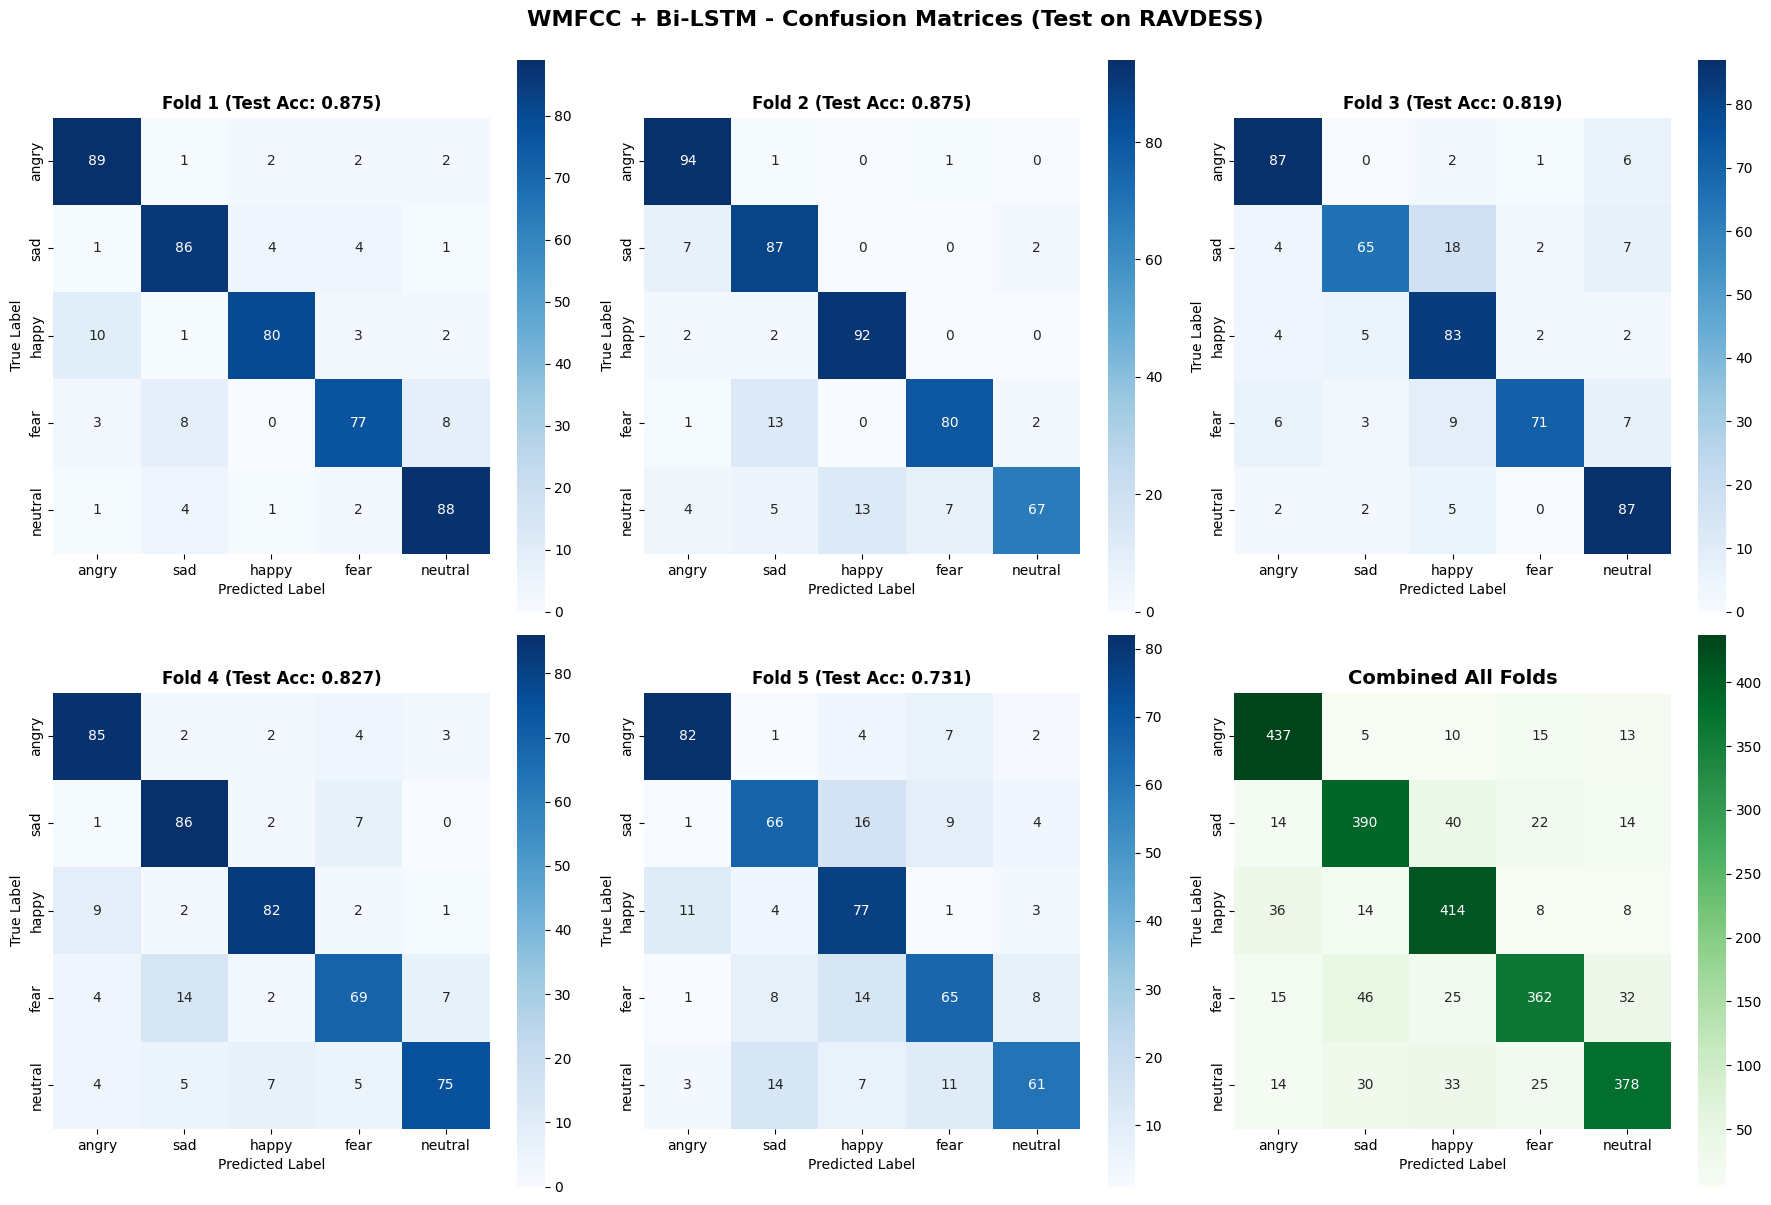


WMFCC + Bi-LSTM - Classification Report (All Folds Combined - HINDI Test Set):
              precision    recall  f1-score   support

       angry     0.8469    0.9104    0.8775       480
         sad     0.8041    0.8125    0.8083       480
       happy     0.7931    0.8625    0.8263       480
        fear     0.8380    0.7542    0.7939       480
     neutral     0.8494    0.7875    0.8173       480

    accuracy                         0.8254      2400
   macro avg     0.8263    0.8254    0.8247      2400
weighted avg     0.8263    0.8254    0.8247      2400



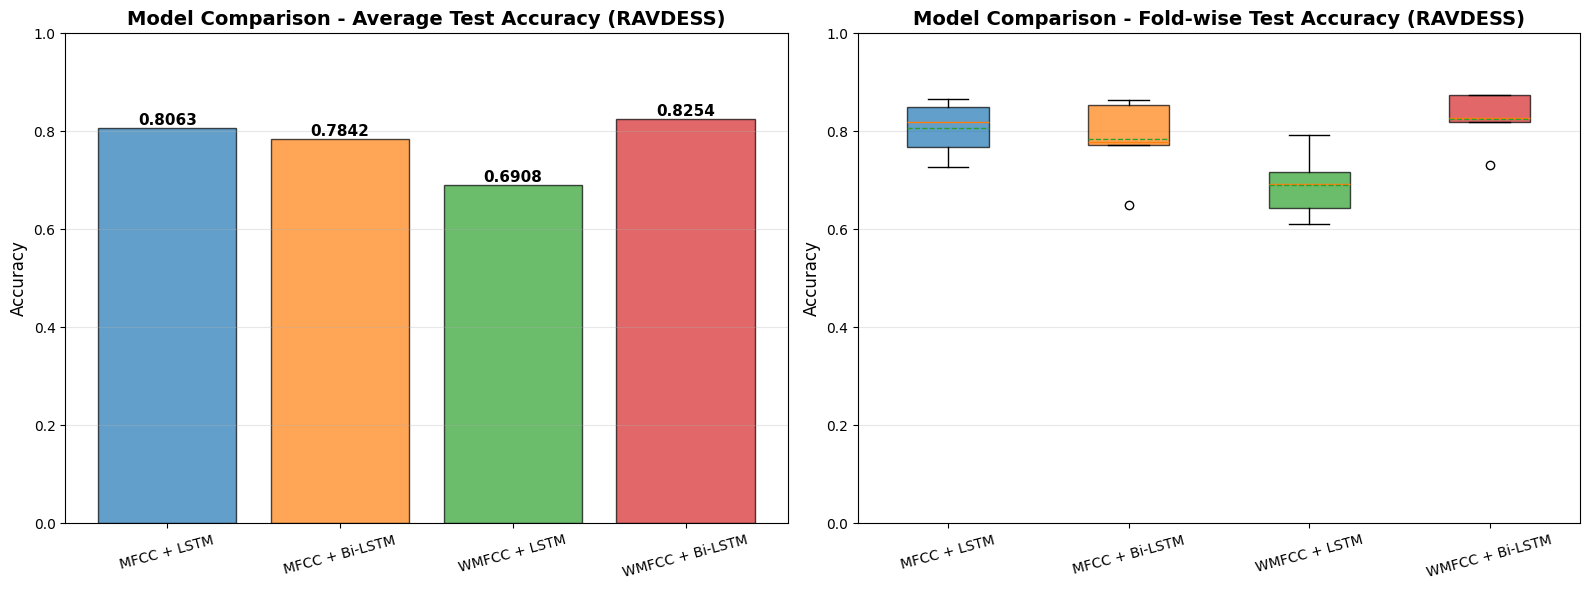

In [ ]:
import os
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.preprocessing import LabelEncoder
import warnings
warnings.filterwarnings('ignore')

# TensorFlow and Keras
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Bidirectional, Dense, Dropout, BatchNormalization
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# =====================================================================
# VISUALIZATION FUNCTIONS
# =====================================================================

def plot_training_history_all_folds(all_histories, model_name):
    """Plot training history showing all folds"""
    fig, axes = plt.subplots(1, 2, figsize=(16, 5))

    # Plot accuracy
    for fold_idx, history in enumerate(all_histories, 1):
        axes[0].plot(history.history['accuracy'], alpha=0.5, label=f'Fold {fold_idx} Train')
        axes[0].plot(history.history['val_accuracy'], alpha=0.5, linestyle='--', label=f'Fold {fold_idx} Test')

    axes[0].set_title(f'{model_name} - Accuracy (All Folds)', fontsize=14, fontweight='bold')
    axes[0].set_xlabel('Epoch', fontsize=12)
    axes[0].set_ylabel('Accuracy', fontsize=12)
    axes[0].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    axes[0].grid(True, alpha=0.3)

    # Plot loss
    for fold_idx, history in enumerate(all_histories, 1):
        axes[1].plot(history.history['loss'], alpha=0.5, label=f'Fold {fold_idx} Train')
        axes[1].plot(history.history['val_loss'], alpha=0.5, linestyle='--', label=f'Fold {fold_idx} Test')

    axes[1].set_title(f'{model_name} - Loss (All Folds)', fontsize=14, fontweight='bold')
    axes[1].set_xlabel('Epoch', fontsize=12)
    axes[1].set_ylabel('Loss', fontsize=12)
    axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.savefig(f'/content/{model_name.replace(" ", "_")}_training_history.png', dpi=300, bbox_inches='tight')
    plt.show()

def plot_confusion_matrix_all_folds(fold_results, model_name):
    """Plot confusion matrices for all folds"""
    n_folds = len(fold_results)
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.flatten()

    emotion_names = list(EMOTION_LABELS.keys())

    # Plot each fold
    for idx, result in enumerate(fold_results):
        cm = confusion_matrix(result['y_true'], result['y_pred'])

        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx],
                   xticklabels=emotion_names, yticklabels=emotion_names,
                   cbar=True, square=True)
        axes[idx].set_title(f'Fold {result["fold"]} (Test Acc: {result["test_acc"]:.3f})', fontweight='bold')
        axes[idx].set_ylabel('True Label')
        axes[idx].set_xlabel('Predicted Label')

    # Plot average confusion matrix
    all_true = np.concatenate([r['y_true'] for r in fold_results])
    all_pred = np.concatenate([r['y_pred'] for r in fold_results])
    cm_avg = confusion_matrix(all_true, all_pred)

    sns.heatmap(cm_avg, annot=True, fmt='d', cmap='Greens', ax=axes[n_folds],
               xticklabels=emotion_names, yticklabels=emotion_names,
               cbar=True, square=True)
    axes[n_folds].set_title('Combined All Folds', fontweight='bold', fontsize=14)
    axes[n_folds].set_ylabel('True Label')
    axes[n_folds].set_xlabel('Predicted Label')

    # Hide the last subplot if not needed
    if n_folds < 5:
        axes[-1].axis('off')

    fig.suptitle(f'{model_name} - Confusion Matrices (Test on RAVDESS)', fontsize=16, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.savefig(f'/content/{model_name.replace(" ", "_")}_confusion_matrices.png', dpi=300, bbox_inches='tight')
    plt.show()

def plot_model_comparison(all_model_results):
    """
    Plot comparison of all 4 models
    """
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    model_names = list(all_model_results.keys())
    avg_accs = [all_model_results[m]['avg_test_acc'] for m in model_names]

    # Bar chart of average accuracies
    colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
    bars = axes[0].bar(model_names, avg_accs, color=colors, alpha=0.7, edgecolor='black')
    axes[0].set_title('Model Comparison - Average Test Accuracy (RAVDESS)', fontsize=14, fontweight='bold')
    axes[0].set_ylabel('Accuracy', fontsize=12)
    axes[0].set_ylim([0, 1])
    axes[0].grid(axis='y', alpha=0.3)
    axes[0].tick_params(axis='x', rotation=15)

    # Add value labels on bars
    for bar, acc in zip(bars, avg_accs):
        height = bar.get_height()
        axes[0].text(bar.get_x() + bar.get_width()/2., height,
                    f'{acc:.4f}',
                    ha='center', va='bottom', fontsize=11, fontweight='bold')

    # Box plot showing fold-wise variation
    fold_accs = [[r['test_acc'] for r in all_model_results[m]['fold_results']]
                 for m in model_names]

    bp = axes[1].boxplot(fold_accs, labels=model_names, patch_artist=True,
                         showmeans=True, meanline=True)

    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    axes[1].set_title('Model Comparison - Fold-wise Test Accuracy (RAVDESS)', fontsize=14, fontweight='bold')
    axes[1].set_ylabel('Accuracy', fontsize=12)
    axes[1].set_ylim([0, 1])
    axes[1].grid(axis='y', alpha=0.3)
    axes[1].tick_params(axis='x', rotation=15)

    plt.tight_layout()
    plt.savefig('/content/model_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()

def main():
    """Main execution function - Train on Both, Test on Hindi ONLY"""

    print("\n" + "="*70)
    print("MULTILINGUAL SPEECH EMOTION RECOGNITION SYSTEM")
    print("TRAIN ON BOTH DATASETS, TEST ON HINDI (IESC) ONLY")
    print("="*70 + "\n")

    # ===== STEP 1: Load Data =====
    ravdess_data, iesc_data = load_all_data()

    all_model_results = {}
    models_to_train = [
        ('MFCC', 'LSTM', 'mfcc', build_lstm_model),
        ('MFCC', 'Bi-LSTM', 'mfcc', build_bilstm_model),
        ('WMFCC', 'LSTM', 'wmfcc', build_lstm_model),
        ('WMFCC', 'Bi-LSTM', 'wmfcc', build_bilstm_model),
    ]

    features_cache = {}

    for feature_name, model_type, feature_type, model_builder in models_to_train:
        model_name = f"{feature_name} + {model_type}"
        print("\n" + "█"*70 + f"\n█  MODEL: {model_name}\n" + "█"*70)

        if feature_type not in features_cache:
            X, y, lang_tags = extract_features_with_augmentation(
                ravdess_data, iesc_data, feature_type=feature_type
            )
            # FORCE Y TO INTEGERS if it is one-hot
            if len(y.shape) > 1:
                y = np.argmax(y, axis=1)
            features_cache[feature_type] = (X, y, lang_tags)
        else:
            X, y, lang_tags = features_cache[feature_type]

        # Filter indices
        hindi_indices = np.where(lang_tags == 'hindi')[0]
        english_indices = np.where(lang_tags == 'english')[0]

        print(f"Total English (RAVDESS) samples: {len(english_indices)}")
        print(f"Total Hindi (IESC) samples: {len(hindi_indices)}")

        from sklearn.model_selection import StratifiedKFold
        skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

        fold_results = []
        all_histories = []

        # Split Hindi into 5 folds
        for fold, (hi_train_idx, hi_test_idx) in enumerate(skf.split(hindi_indices, y[hindi_indices]), 1):
            print(f"\n" + "─"*70 + f"\nFOLD {fold}/5\n" + "─"*70)

            actual_hi_train = hindi_indices[hi_train_idx]
            actual_hi_test = hindi_indices[hi_test_idx]

            # Combine: 100% English + 80% Hindi for training
            train_idx = np.concatenate([actual_hi_train, english_indices])
            test_idx = actual_hi_test

            # Build and train
            model = model_builder((X.shape[1], X.shape[2]), len(EMOTION_LABELS))
            early_stop = EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True)

            history = model.fit(
                X[train_idx], to_categorical(y[train_idx], num_classes=len(EMOTION_LABELS)),
                validation_split=0.1,
                epochs=EPOCHS,
                batch_size=BATCH_SIZE,
                callbacks=[early_stop],
                verbose=1
            )

            # Evaluate on HINDI ONLY
            y_pred = np.argmax(model.predict(X[test_idx]), axis=1)
            y_true = y[test_idx]
            test_acc = accuracy_score(y_true, y_pred)

            fold_results.append({'fold': fold, 'test_acc': test_acc, 'y_true': y_true, 'y_pred': y_pred})
            all_histories.append(history)
            print(f"Fold {fold} Test Accuracy: {test_acc:.4f}")

        # Visualizations (Updates labels to HINDI)
        plot_training_history_all_folds(all_histories, model_name)
        # Suggestion: Update your plot functions to take a 'test_set_name' argument
        plot_confusion_matrix_all_folds(fold_results, model_name)

        # Classification Report
        all_true = np.concatenate([r['y_true'] for r in fold_results])
        all_pred = np.concatenate([r['y_pred'] for r in fold_results])
        print(f"\n{model_name} - Classification Report (HINDI Test Set):")
        print("="*70)
        print(classification_report(all_true, all_pred, target_names=list(EMOTION_LABELS.keys()), digits=4))

        all_model_results[model_name] = {'avg_test_acc': np.mean([r['test_acc'] for r in fold_results]), 'fold_results': fold_results}

    plot_model_comparison(all_model_results)

    return all_model_results # Added this line to return the results


In [ ]:
print("\n--- Model Performance Summary (Test on Hindi) ---")
for model_name, results in all_model_results.items():
    print(f"{model_name}: Average Test Accuracy = {results['avg_test_acc']:.4f}")
print("--------------------------------------------------")



--- Model Performance Summary (Test on Hindi) ---


NameError: name 'all_model_results' is not defined

In [ ]:
all_model_results = main()